# Task 3: Data augmentation study

**Objective:** increase validation accuracy (if possible) with data augmentation, and report
how each augmentation parameter affects validation accuracy.

Adam Oakes

**Setup**
* Same CNN as the Task 2 best model (5 conv blocks, 32→512 filters, GAP, sigmoid).
* Same optimizer (Adam), batch size (64), epochs (4) and early-stopping rule as Task 2.
* Every configuration trains a **fresh model from the same random seed**, so the only thing
  that changes between rows of the results table is the augmentation.
* The baseline (no augmentation) is trained twice with two different seeds. The gap between
  those two runs is the **noise floor**: a change smaller than that gap may be luck, not a real effect.

**About "image generators":** `ImageDataGenerator` is deprecated and was removed in Keras 3.
The replacements are Keras preprocessing layers (`RandomFlip`, `RandomRotation`, `RandomZoom`, ...).
They do the same job, and each row of the table lists the matching `ImageDataGenerator` argument.

**Pipeline note:** the CIFAKE images are 32×32. The previous notebooks had
`image_dataset_from_directory` upsample them to 180×180 on the CPU, and the earlier augmented run
applied the augmentation in `dataset.map` to those 180×180 tensors. That is why each epoch took
about 1400 s instead of about 40 s. Here the images load at their native 32×32 and are cached in
memory. Augmentation and the 32→180 bilinear upsample both happen **inside the model**, so they
run on the GPU. Augmentation layers are only active while training, so validation images go
through exactly the same path as in Task 2.

# Library imports and configuration

In [1]:
import os, json, time
from pathlib import Path

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TASK = "task_3"
DATA_DIR = Path(os.environ.get("DATA_DIR", "../data"))
EPOCHS = int(os.environ.get("EPOCHS", 4))          # same as Task 2
BATCH_SIZE = 64
NATIVE_SIZE = (32, 32)    # CIFAKE images are 32x32
MODEL_SIZE = (180, 180)   # same input size the Task 2 architecture was designed for
SEED = 42
SECOND_SEED = 7           # second baseline run -> noise floor

OUT = Path(os.environ.get("OUT_DIR", ".."))
plots = OUT / "plots" / TASK
results_dir = OUT / "results" / TASK
for d in (plots, results_dir):
    d.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = results_dir / "augmentation_results.csv"
HISTORY_JSON = results_dir / "augmentation_histories.json"
print("results ->", RESULTS_CSV.resolve())

results -> /Users/adamoakes/classes/DL/Projects/Real_vs_Fake_Classifier/results/task_3/augmentation_results.csv


# Load the data (native 32×32, cached in memory)

In [2]:
def load(split, shuffle):
    return image_dataset_from_directory(
        DATA_DIR / split, image_size=NATIVE_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED,
    )

train_dataset = load("train", shuffle=True)
validation_dataset = load("validation", shuffle=False)
class_names = train_dataset.class_names
print(class_names)

# ~1 GB of RAM for 80k 32x32 float images; avoids decoding 80k JPEGs every epoch.
# The training set is reshuffled every epoch after the cache.
train_ds = (train_dataset.unbatch().cache()
            .shuffle(20_000, seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = validation_dataset.cache().prefetch(tf.data.AUTOTUNE)

Found 80000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
['FAKE', 'REAL']


# Augmentation configurations

Each transform is first tested **by itself**, at several strengths, so its effect can be
isolated. Two combinations come after that:
* the "book" pipeline from the course notebook (flip + rotation 0.1 + zoom 0.2), and
* an automatically built **best-of** pipeline that combines the strongest setting from every
  transform family that beat the baseline.

Keras factors are fractions, not degrees. For example, `RandomRotation(0.1)` rotates by up to
±0.1·360° = ±36°, and `RandomTranslation(0.1, 0.1)` shifts by up to ±10% of the height and width.

In [3]:
# name -> (family, list of layer factories, ImageDataGenerator equivalent)
CONFIGS = {
    "baseline":            ("none",        [], "-"),
    f"baseline_seed{SECOND_SEED}": ("none", [], "- (noise-floor rerun)"),

    "flip_h":              ("flip",        [lambda: layers.RandomFlip("horizontal")], "horizontal_flip=True"),
    "flip_hv":             ("flip",        [lambda: layers.RandomFlip("horizontal_and_vertical")], "horizontal_flip=True, vertical_flip=True"),

    "rot_0.05":            ("rotation",    [lambda: layers.RandomRotation(0.05)], "rotation_range=18"),
    "rot_0.10":            ("rotation",    [lambda: layers.RandomRotation(0.10)], "rotation_range=36"),
    "rot_0.20":            ("rotation",    [lambda: layers.RandomRotation(0.20)], "rotation_range=72"),

    "zoom_0.1":            ("zoom",        [lambda: layers.RandomZoom(0.1)], "zoom_range=0.1"),
    "zoom_0.2":            ("zoom",        [lambda: layers.RandomZoom(0.2)], "zoom_range=0.2"),
    "zoom_0.3":            ("zoom",        [lambda: layers.RandomZoom(0.3)], "zoom_range=0.3"),

    "shift_0.1":           ("translation", [lambda: layers.RandomTranslation(0.1, 0.1)], "width_shift_range=0.1, height_shift_range=0.1"),
    "shift_0.2":           ("translation", [lambda: layers.RandomTranslation(0.2, 0.2)], "width_shift_range=0.2, height_shift_range=0.2"),

    "brightness_0.2":      ("brightness",  [lambda: layers.RandomBrightness(0.2, value_range=(0, 255))], "brightness_range=[0.8, 1.2]"),
    "contrast_0.2":        ("contrast",    [lambda: layers.RandomContrast(0.2)], "- (no direct equivalent)"),
    # Keras 3 requires GaussianNoise stddev in [0, 1], so scale to [0, 1], add noise (0.02 ~ 5/255), scale back
    "noise_0.02":          ("noise",       [lambda: layers.Rescaling(1 / 255),
                                            lambda: layers.GaussianNoise(0.02),
                                            lambda: layers.Rescaling(255)], "- (no direct equivalent)"),

    "book_combo":          ("combo",       [lambda: layers.RandomFlip("horizontal"),
                                            lambda: layers.RandomRotation(0.1),
                                            lambda: layers.RandomZoom(0.2)],
                            "horizontal_flip=True, rotation_range=36, zoom_range=0.2"),
}
print(len(CONFIGS), "configurations (+1 auto best-of combo)")

16 configurations (+1 auto best-of combo)


## What each augmentation does to an image

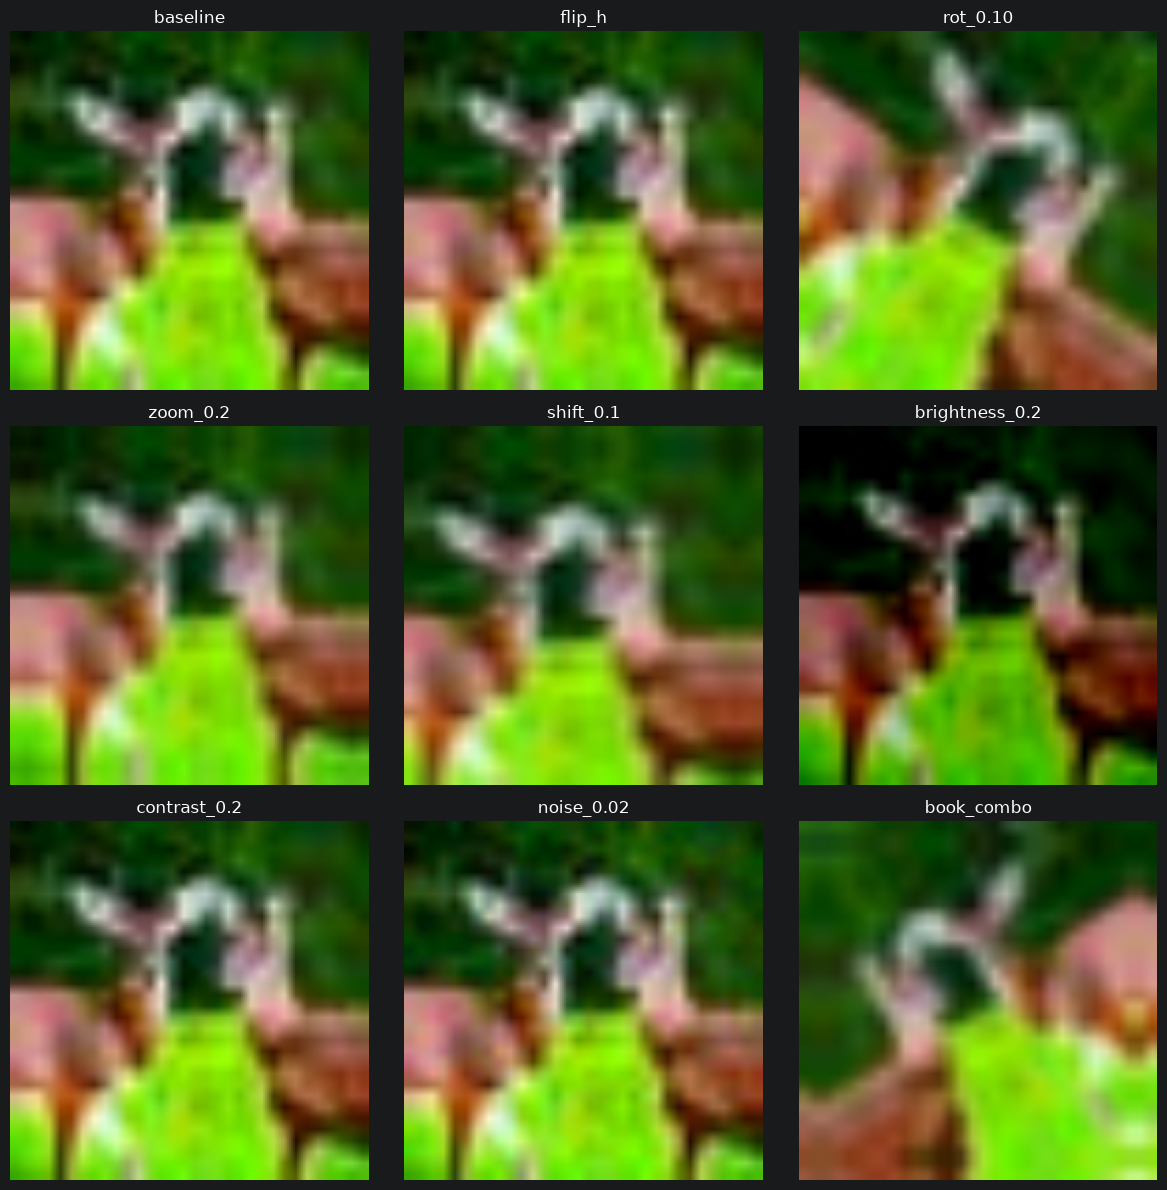

In [4]:
sample = next(iter(validation_dataset.take(1)))[0][:1]   # one image, native 32x32
upsample = layers.Resizing(*MODEL_SIZE, interpolation="bilinear")
show = ["baseline", "flip_h", "rot_0.10", "zoom_0.2", "shift_0.1",
        "brightness_0.2", "contrast_0.2", "noise_0.02", "book_combo"]
plt.figure(figsize=(12, 12))
for i, name in enumerate(show):
    aug = keras.Sequential([f() for f in CONFIGS[name][1]])
    img = aug(sample, training=True) if CONFIGS[name][1] else sample
    img = keras.ops.convert_to_numpy(upsample(img))[0]
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(np.clip(img, 0, 255).astype("uint8"))
    plt.title(name); plt.axis("off")
plt.tight_layout()
plt.savefig(plots / "augmentation_examples.png", dpi=120)
plt.show()

# Model: the Task 2 architecture with an augmentation stage at the front

In [5]:
def build_model(aug_factories, name):
    inputs = keras.Input(shape=NATIVE_SIZE + (3,))
    x = inputs
    for make in aug_factories:            # training-only; identity at inference
        x = make()(x)
    x = layers.Resizing(*MODEL_SIZE, interpolation="bilinear")(x)   # same 32->180 upsample as Task 2
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(256, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(512, 3, activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs, name=name.replace(".", "p"))
    model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model

build_model(CONFIGS["book_combo"][1], "preview").summary()

Model: "preview"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_2 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_1 (Resizing)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,569,089 (5.99 MB)

 Trainable params: 1,569,089 (5.99 MB)

 Non-trainable params: 0 (0.00 B)

# Run the sweep

The results go to a CSV **after every configuration**. If the kernel dies or you stop it,
re-running this cell skips the configurations that already finished. To start over, delete
`results/task_3/augmentation_results.csv`.

Expect about 3–4 minutes per configuration on the GPU (the same speed as Task 2).

In [ ]:
def load_results():
    if RESULTS_CSV.exists():
        return pd.read_csv(RESULTS_CSV)
    return pd.DataFrame()

def load_histories():
    return json.loads(HISTORY_JSON.read_text()) if HISTORY_JSON.exists() else {}

def run_config(name, family, factories, idg_equiv, seed=SEED):
    done = load_results()
    if len(done) and name in set(done["config"]):
        print(f"skip {name} (already done)")
        return
    keras.utils.set_random_seed(seed)
    model = build_model(factories, name)
    cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                        mode="max", restore_best_weights=True)]
    t0 = time.time()
    h = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds, callbacks=cb, verbose=2)
    secs = time.time() - t0
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best = int(np.argmax(hist["val_accuracy"]))
    row = dict(
        config=name, family=family, idg_equivalent=idg_equiv, seed=seed,
        best_val_acc=hist["val_accuracy"][best], best_epoch=best + 1,
        best_val_loss=hist["val_loss"][best],
        final_val_acc=hist["val_accuracy"][-1],
        final_train_acc=hist["accuracy"][-1],
        sec_per_epoch=secs / len(hist["accuracy"]),
    )
    pd.concat([done, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)
    hs = load_histories(); hs[name] = hist
    HISTORY_JSON.write_text(json.dumps(hs))
    print(f"==> {name}: best val_acc {row['best_val_acc']:.4f} (epoch {row['best_epoch']})")

for name, (family, factories, idg) in CONFIGS.items():
    seed = SECOND_SEED if name.startswith("baseline_seed") else SEED
    run_config(name, family, factories, idg, seed=seed)

Epoch 1/4


/Users/adamoakes/classes/DL/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1250/1250 - 1282s - 1s/step - accuracy: 0.8040 - loss: 0.4282 - val_accuracy: 0.8466 - val_loss: 0.3559
Epoch 2/4
1250/1250 - 1317s - 1s/step - accuracy: 0.8834 - loss: 0.2842 - val_accuracy: 0.9092 - val_loss: 0.2305
Epoch 3/4
1250/1250 - 1359s - 1s/step - accuracy: 0.9033 - loss: 0.2384 - val_accuracy: 0.8993 - val_loss: 0.2371
Epoch 4/4
1250/1250 - 1382s - 1s/step - accuracy: 0.9157 - loss: 0.2109 - val_accuracy: 0.9177 - val_loss: 0.2100
==> baseline: best val_acc 0.9177 (epoch 4)
Epoch 1/4


/Users/adamoakes/classes/DL/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


## Auto "best-of" combination

For every single-transform family, take the best setting **only if** it beat the baseline by
more than the noise floor. Combine those settings into one pipeline and train it.

In [ ]:
res = load_results()
base = res.loc[res.config == "baseline", "best_val_acc"].item()
noise = abs(base - res.loc[res.config.str.startswith("baseline_seed"), "best_val_acc"].item())
singles = res[~res.family.isin(["none", "combo"])]
winners = (singles.sort_values("best_val_acc", ascending=False)
                  .groupby("family").head(1))
winners = winners[winners.best_val_acc - base > noise]
print(f"baseline {base:.4f}, noise floor ±{noise:.4f}")
print("families that beat the baseline by more than the noise floor:", list(winners.config))

if len(winners) >= 2:
    facs = [f for c in winners.config for f in CONFIGS[c][1]]
    idg = " + ".join(CONFIGS[c][2] for c in winners.config)
    CONFIGS["best_of_combo"] = ("combo", facs, idg)
    run_config("best_of_combo", "combo", facs, idg)
else:
    print("Fewer than two families clearly helped, so there is nothing to combine; skipping best-of combo.")

# Results table

In [ ]:
res = load_results()
base = res.loc[res.config == "baseline", "best_val_acc"].item()
res["delta_vs_baseline"] = res.best_val_acc - base
res["overfit_gap"] = res.final_train_acc - res.final_val_acc
order = ["none", "flip", "rotation", "zoom", "translation", "brightness", "contrast", "noise", "combo"]
res["family"] = pd.Categorical(res.family, order, ordered=True)
table = res.sort_values(["family", "config"])[
    ["family", "config", "idg_equivalent", "best_val_acc", "delta_vs_baseline",
     "best_epoch", "final_train_acc", "overfit_gap", "sec_per_epoch"]]

def to_markdown(df):
    fmt = {"best_val_acc": "{:.4f}", "delta_vs_baseline": "{:+.4f}", "final_train_acc": "{:.4f}",
           "overfit_gap": "{:+.4f}", "sec_per_epoch": "{:.0f}"}
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(fmt.get(c, "{}").format(r[c]) for c in cols) + " |")
    return "\n".join(lines)

md_table = to_markdown(table)
(results_dir / "augmentation_results.md").write_text(md_table)
from IPython.display import Markdown, display
display(Markdown(md_table))

# Plots

In [ ]:
# Validation accuracy per configuration, measured against the baseline and its noise band
t = res.sort_values("best_val_acc")
noise = abs(base - res.loc[res.config.str.startswith("baseline_seed"), "best_val_acc"].item())
colors = ["#8a8a8a" if f == "none" else ("#2a6fdb" if d > noise else "#c9c9c9")
          for f, d in zip(t.family, t.delta_vs_baseline)]
fig, ax = plt.subplots(figsize=(8, 0.38 * len(t) + 1.2))
ax.barh(t.config, t.best_val_acc, color=colors, height=0.7)
ax.axvspan(base - noise, base + noise, color="#000", alpha=0.07, lw=0)
ax.axvline(base, color="#444", lw=1, ls="--")
for y, (v, d) in enumerate(zip(t.best_val_acc, t.delta_vs_baseline)):
    ax.text(v + 0.002, y, f"{v:.3f} ({d:+.3f})", va="center", fontsize=8, color="#333")
lo = max(0.5, t.best_val_acc.min() - 0.03)
ax.set_xlim(lo, min(1.0, t.best_val_acc.max() + 0.04))
ax.set_xlabel("best validation accuracy")
ax.set_title("Effect of each augmentation on validation accuracy\n"
             "dashed = baseline, shaded = noise floor, blue = beats noise floor", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig(plots / "val_acc_by_augmentation.png", dpi=150)
plt.show()

In [ ]:
# Validation-accuracy curves, one panel per transform family (baseline drawn in every panel)
hs = load_histories()
fams = [f for f in order if f != "none" and f in set(res.family.astype(str))]
fig, axes = plt.subplots(2, (len(fams) + 1) // 2, figsize=(14, 6), sharey=True)
for ax, fam in zip(axes.flat, fams):
    ep = range(1, len(hs["baseline"]["val_accuracy"]) + 1)
    ax.plot(ep, hs["baseline"]["val_accuracy"], color="#444", ls="--", lw=1.5, label="baseline")
    for c in res.loc[res.family == fam, "config"]:
        v = hs[c]["val_accuracy"]
        ax.plot(range(1, len(v) + 1), v, lw=2, marker="o", ms=4, label=c)
    ax.set_title(fam); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
for ax in list(axes.flat)[len(fams):]: ax.axis("off")
axes.flat[0].set_ylabel("validation accuracy")
plt.tight_layout()
fig.savefig(plots / "val_curves_by_family.png", dpi=150)
plt.show()

# Discussion

**What to look for in the table.** This task is not the usual cats-vs-dogs case where the
classes differ in object shape. Here the classes differ in *how the pixels were produced*: a
camera or a diffusion model. The cues a CNN can use include fine textures, noise statistics and
upsampling artifacts, which live at the 1–2 pixel scale of a 32×32 image. That leads to three
predictions to test against the results:

1. **Exact transforms** (horizontal flip) move pixels around without resampling them, so they
   keep those fine-scale cues. They should be neutral to helpful.
2. **Resampling transforms** (rotation, zoom, sub-pixel shifts) interpolate between pixels,
   which blurs exactly those cues. They may *hurt*, and more so at higher strength. They also
   teach the model that interpolated images are "normal", which the validation set never shows.
3. **Additive noise** directly covers up the noise signature, so it should hurt the most.

Also compare `overfit_gap` across rows. With 80k training images and only 4 epochs, the baseline
may barely be overfitting. In that case augmentation has no overfitting to fix, and you would
expect it to slow down learning in the first epochs rather than raise the ceiling. A longer run
(for example, `EPOCHS=15`) is the fair way to test whether augmentation pays off once the
baseline starts to overfit.

*Fill in your observations here once the run finishes.*

In [ ]:
best = res.sort_values("best_val_acc", ascending=False).iloc[0]
print(f"Baseline:            {base:.4f}  (noise floor ±{noise:.4f})")
print(f"Best configuration:  {best.config}  {best.best_val_acc:.4f}  ({best.best_val_acc - base:+.4f})")
print("Beat the baseline by more than the noise floor:",
      list(res.loc[res.delta_vs_baseline > noise, "config"]))
print("Hurt by more than the noise floor:",
      list(res.loc[res.delta_vs_baseline < -noise, "config"]))